In [ ]:


# Basic libraries
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

# Machine Learning
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler, label_binarize
from sklearn.impute import SimpleImputer

# Models
from sklearn.linear_model import LogisticRegression
from sklearn.neighbors import KNeighborsClassifier
from sklearn.ensemble import RandomForestClassifier
from sklearn.svm import SVC
from sklearn.tree import DecisionTreeClassifier

# Evaluation
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    classification_report,
    confusion_matrix,
    roc_curve,
    auc,
    roc_auc_score
)

# 3D plotting
from mpl_toolkits.mplot3d import Axes3D

import warnings
warnings.filterwarnings("ignore")

print("All libraries imported successfully!")

All libraries imported successfully!


In [ ]:
# ============================================================
# 1. DATA ACQUISITION
# ============================================================

url = "https://archive.ics.uci.edu/ml/machine-learning-databases/dermatology/dermatology.data"

# Feature names
columns = [
    "erythema",
    "scaling",
    "definite_borders",
    "itching",
    "koebner_phenomenon",
    "polygonal_papules",
    "follicular_papules",
    "oral_mucosal_involvement",
    "knee_elbow_involvement",
    "scalp_involvement",
    "family_history",
    "melanin_incontinence",
    "eosinophils_infiltrate",
    "PNL_infiltrate",
    "fibrosis_papillary_dermis",
    "exocytosis",
    "acanthosis",
    "hyperkeratosis",
    "parakeratosis",
    "clubbing_rete_ridges",
    "elongation_rete_ridges",
    "thinning_suprapapillary_epidermis",
    "spongiform_pustule",
    "munro_microabcess",
    "focal_hypergranulosis",
    "disappearance_granular_layer",
    "vacuolisation_basal_layer",
    "spongiosis",
    "saw_tooth_appearance",
    "follicular_horn_plug",
    "perifollicular_parakeratosis",
    "inflammatory_monoluclear_infiltrate",
    "band_like_infiltrate",
    "age",
    "class"
]

# Load dataset
df = pd.read_csv(
    url,
    header=None,
    names=columns,
    na_values="?"
)

print("Dataset loaded successfully!")
print("Shape:", df.shape)

display(df.head())

Dataset loaded successfully!
Shape: (366, 35)


,erythema,scaling,definite_borders,itching,koebner_phenomenon,polygonal_papules,follicular_papules,oral_mucosal_involvement,knee_elbow_involvement,scalp_involvement,...,disappearance_granular_layer,vacuolisation_basal_layer,spongiosis,saw_tooth_appearance,follicular_horn_plug,perifollicular_parakeratosis,inflammatory_monoluclear_infiltrate,band_like_infiltrate,age,class
0,2,2,0,3,0,0,0,0,1,0,...,0,0,3,0,0,0,1,0,55.0,2
1,3,3,3,2,1,0,0,0,1,1,...,0,0,0,0,0,0,1,0,8.0,1
2,2,1,2,3,1,3,0,3,0,0,...,0,2,3,2,0,0,2,3,26.0,3
3,2,2,2,0,0,0,0,0,3,2,...,3,0,0,0,0,0,3,0,40.0,1
4,2,3,2,2,2,2,0,2,0,0,...,2,3,2,3,0,0,2,3,45.0,3


In [ ]:
# ============================================================
# 2. SUMMARY STATISTICS
# ============================================================

print("========== SUMMARY STATISTICS ==========")

# Numerical summary
summary_statistics = df.describe().T

# Add median
summary_statistics["median"] = df.median(numeric_only=True)

# Reorder columns
summary_statistics = summary_statistics[
    [
        "count",
        "mean",
        "median",
        "std",
        "min",
        "25%",
        "50%",
        "75%",
        "max"
    ]
]

display(summary_statistics)

========== SUMMARY STATISTICS ==========


,count,mean,median,std,min,25%,50%,75%,max
erythema,366.0,2.068306,2.0,0.664753,0.0,2.0,2.0,2.00,3.0
scaling,366.0,1.795082,2.0,0.701527,0.0,1.0,2.0,2.00,3.0
definite_borders,366.0,1.549180,2.0,0.907525,0.0,1.0,2.0,2.00,3.0
itching,366.0,1.366120,1.0,1.138299,0.0,0.0,1.0,2.00,3.0
koebner_phenomenon,366.0,0.633880,0.0,0.908016,0.0,0.0,0.0,1.00,3.0
polygonal_papules,366.0,0.448087,0.0,0.957327,0.0,0.0,0.0,0.00,3.0
follicular_papules,366.0,0.166667,0.0,0.570588,0.0,0.0,0.0,0.00,3.0
oral_mucosal_involvement,366.0,0.377049,0.0,0.834147,0.0,0.0,0.0,0.00,3.0
knee_elbow_involvement,366.0,0.614754,0.0,0.982979,0.0,0.0,0.0,1.00,3.0
scalp_involvement,366.0,0.519126,0.0,0.905639,0.0,0.0,0.0,1.00,3.0


In [ ]:
# ============================================================
# 3. MISSING VALUES
# ============================================================

print("========== MISSING VALUES ==========")

missing_values = df.isnull().sum()

missing_table = pd.DataFrame({
    "Column": missing_values.index,
    "Missing Values": missing_values.values
})

display(missing_table[missing_table["Missing Values"] > 0])

print("\nTotal missing values:", df.isnull().sum().sum())

# ============================================================
# HANDLE MISSING VALUES
# ============================================================

# Separate features and target
X = df.drop("class", axis=1)
y = df["class"]

# Convert all features to numeric
X = X.apply(pd.to_numeric, errors="coerce")

# Median imputation
imputer = SimpleImputer(strategy="median")

X_imputed = pd.DataFrame(
    imputer.fit_transform(X),
    columns=X.columns
)

print("Missing values after imputation:")
print(X_imputed.isnull().sum().sum())

========== MISSING VALUES ==========


,Column,Missing Values
33,age,8



Total missing values: 8
Missing values after imputation:
0


In [ ]:
# ============================================================
# 4. DUPLICATE VALUES
# ============================================================

duplicate_count = df.duplicated().sum()

print("Number of duplicate rows:", duplicate_count)

if duplicate_count > 0:
    df = df.drop_duplicates()
    print("Duplicates removed.")
else:
    print("No duplicate rows found.")

Number of duplicate rows: 0
No duplicate rows found.


In [ ]:
# ============================================================
# 5. OUTLIER DETECTION USING IQR
# ============================================================

Q1 = X_imputed.quantile(0.25)
Q3 = X_imputed.quantile(0.75)

IQR = Q3 - Q1

lower_bound = Q1 - 1.5 * IQR
upper_bound = Q3 + 1.5 * IQR

outlier_count = (
    (X_imputed < lower_bound) |
    (X_imputed > upper_bound)
).sum()

outlier_table = pd.DataFrame({
    "Feature": X_imputed.columns,
    "Outlier Count": outlier_count.values
})

display(outlier_table)

# ============================================================
# OUTLIER HANDLING - IQR CAPPING
# ============================================================

X_clean = X_imputed.copy()

for column in X_clean.columns:
    Q1_col = X_clean[column].quantile(0.25)
    Q3_col = X_clean[column].quantile(0.75)

    IQR_col = Q3_col - Q1_col

    lower = Q1_col - 1.5 * IQR_col
    upper = Q3_col + 1.5 * IQR_col

    X_clean[column] = X_clean[column].clip(
        lower=lower,
        upper=upper
    )

print("Outlier handling completed.")

,Feature,Outlier Count
0,erythema,151
1,scaling,0
2,definite_borders,0
3,itching,0
4,koebner_phenomenon,18
5,polygonal_papules,69
6,follicular_papules,33
7,oral_mucosal_involvement,67
8,knee_elbow_involvement,23
9,scalp_involvement,16


Outlier handling completed.


In [ ]:
class_counts = y.value_counts().sort_index()

class_percentage = (
    y.value_counts(normalize=True)
    .sort_index() * 100
)

class_distribution = pd.DataFrame({
    "Number of Samples": class_counts,
    "Percentage": class_percentage.round(2)
})

display(class_distribution)

,Number of Samples,Percentage
class,,
1,112,30.60
2,61,16.67
3,72,19.67
4,49,13.39
5,52,14.21
6,20,5.46


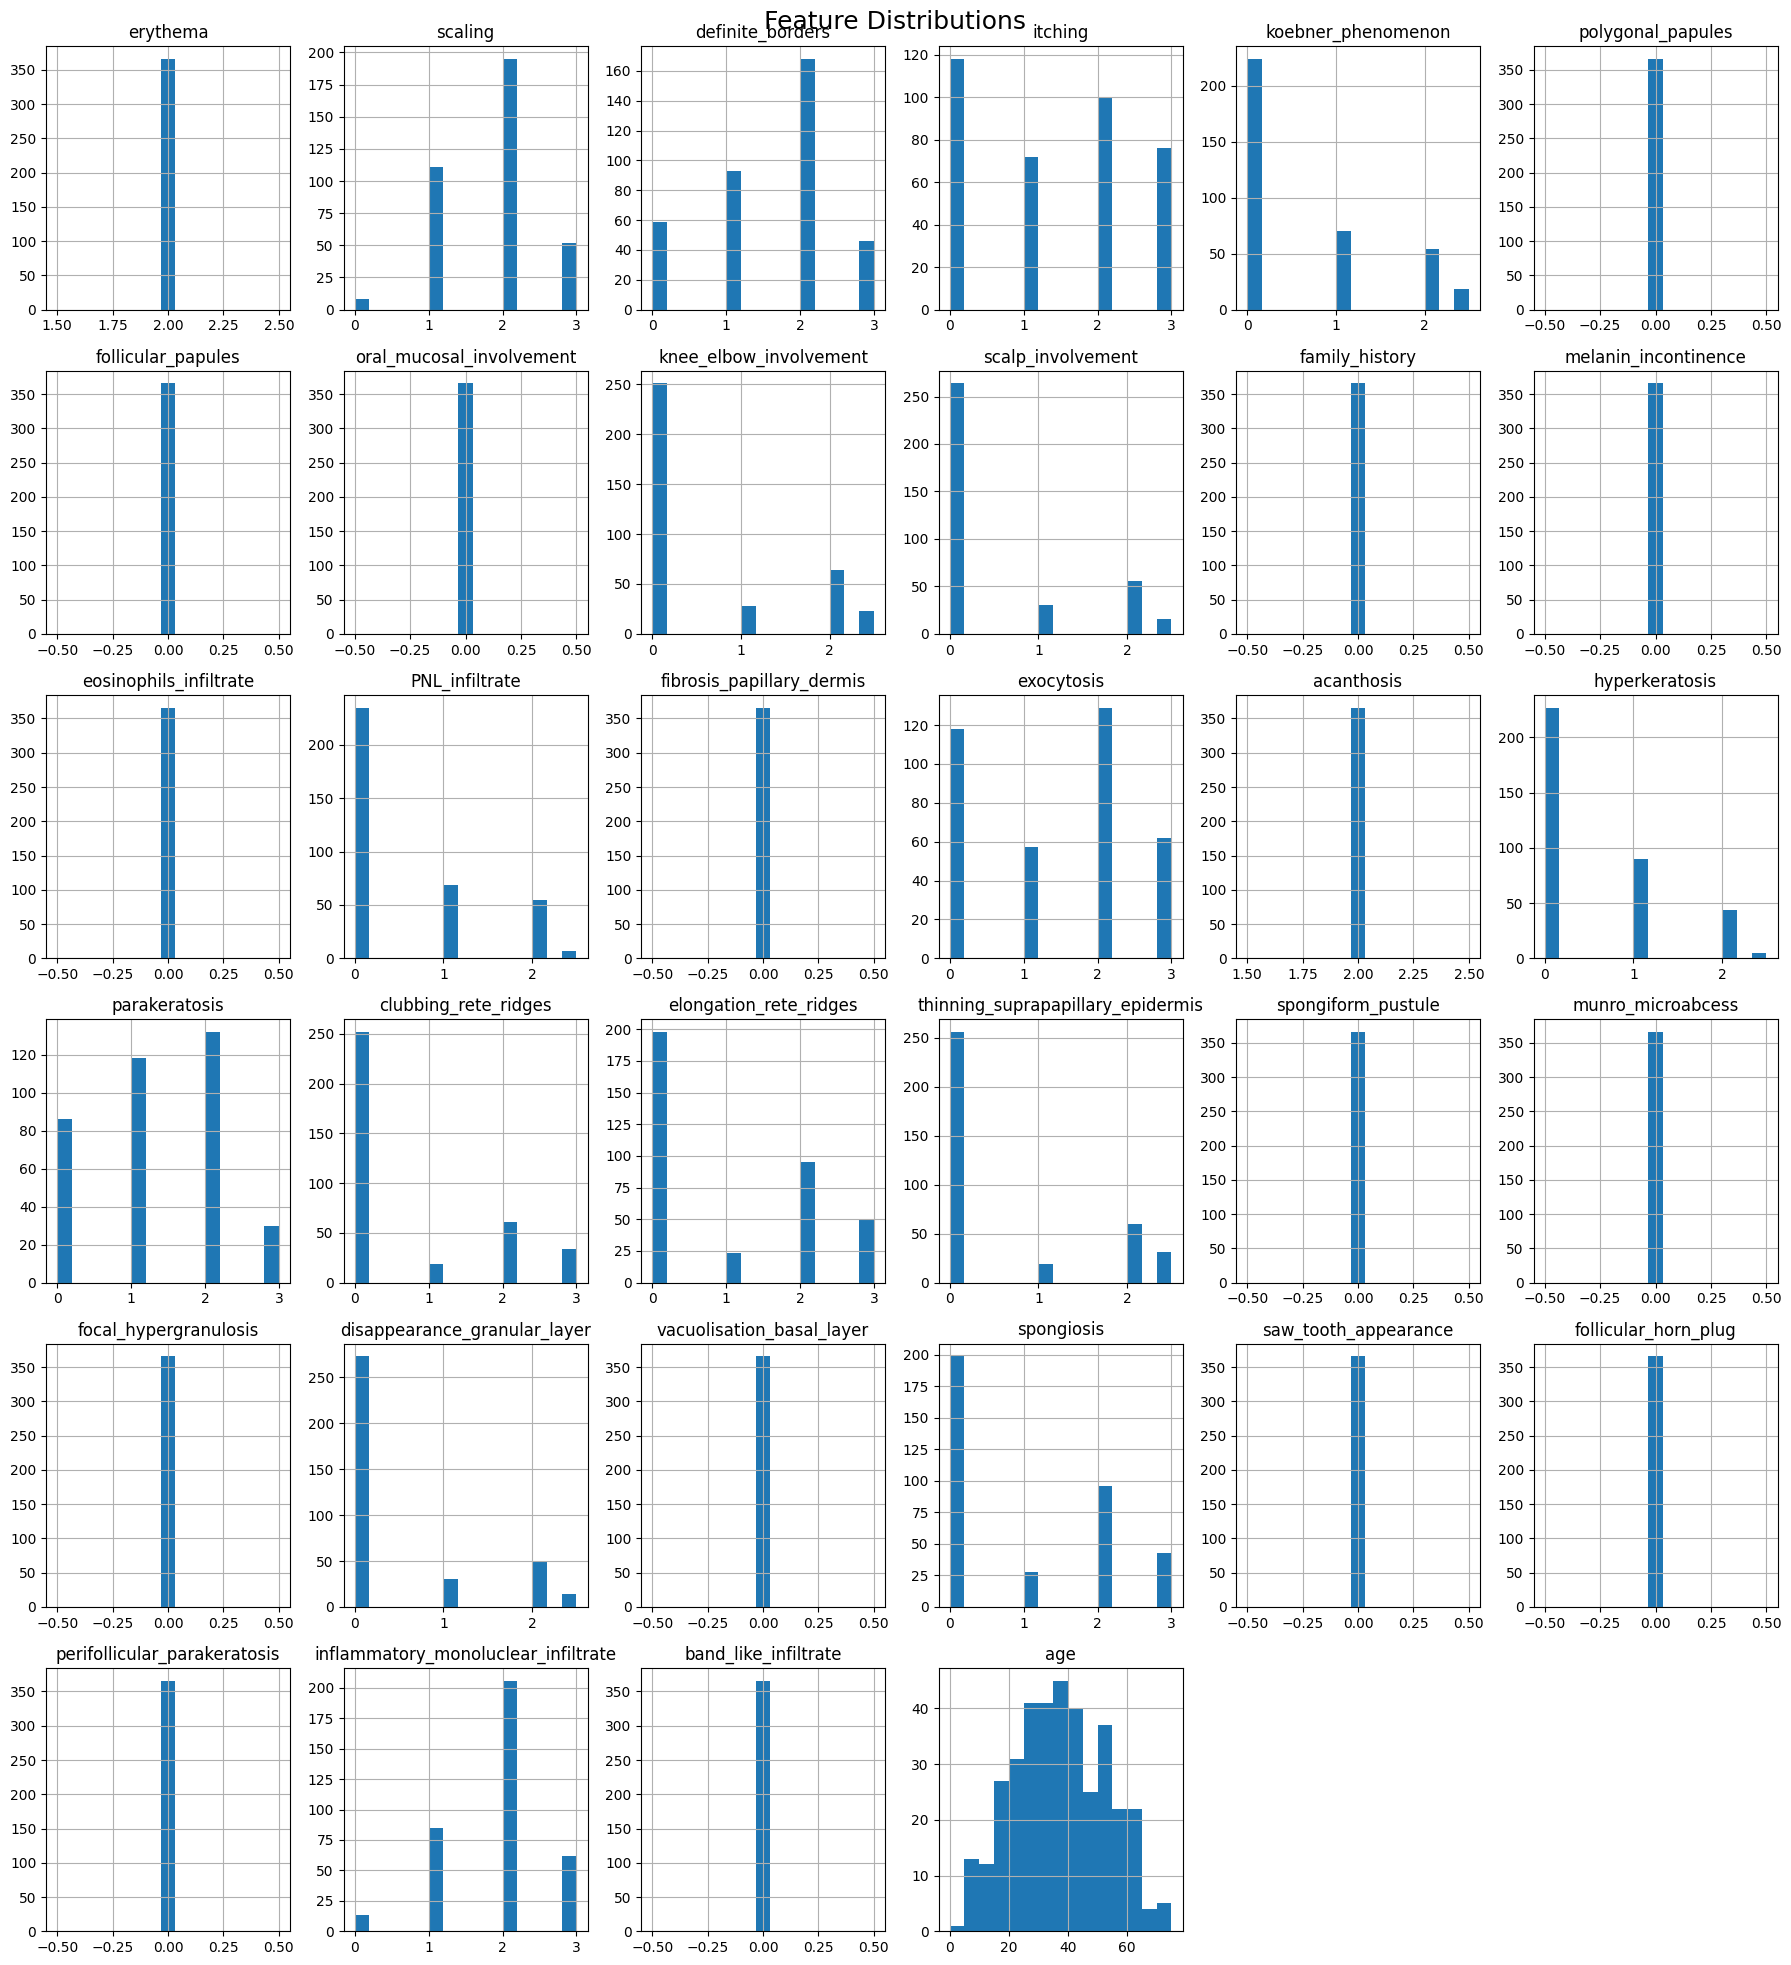

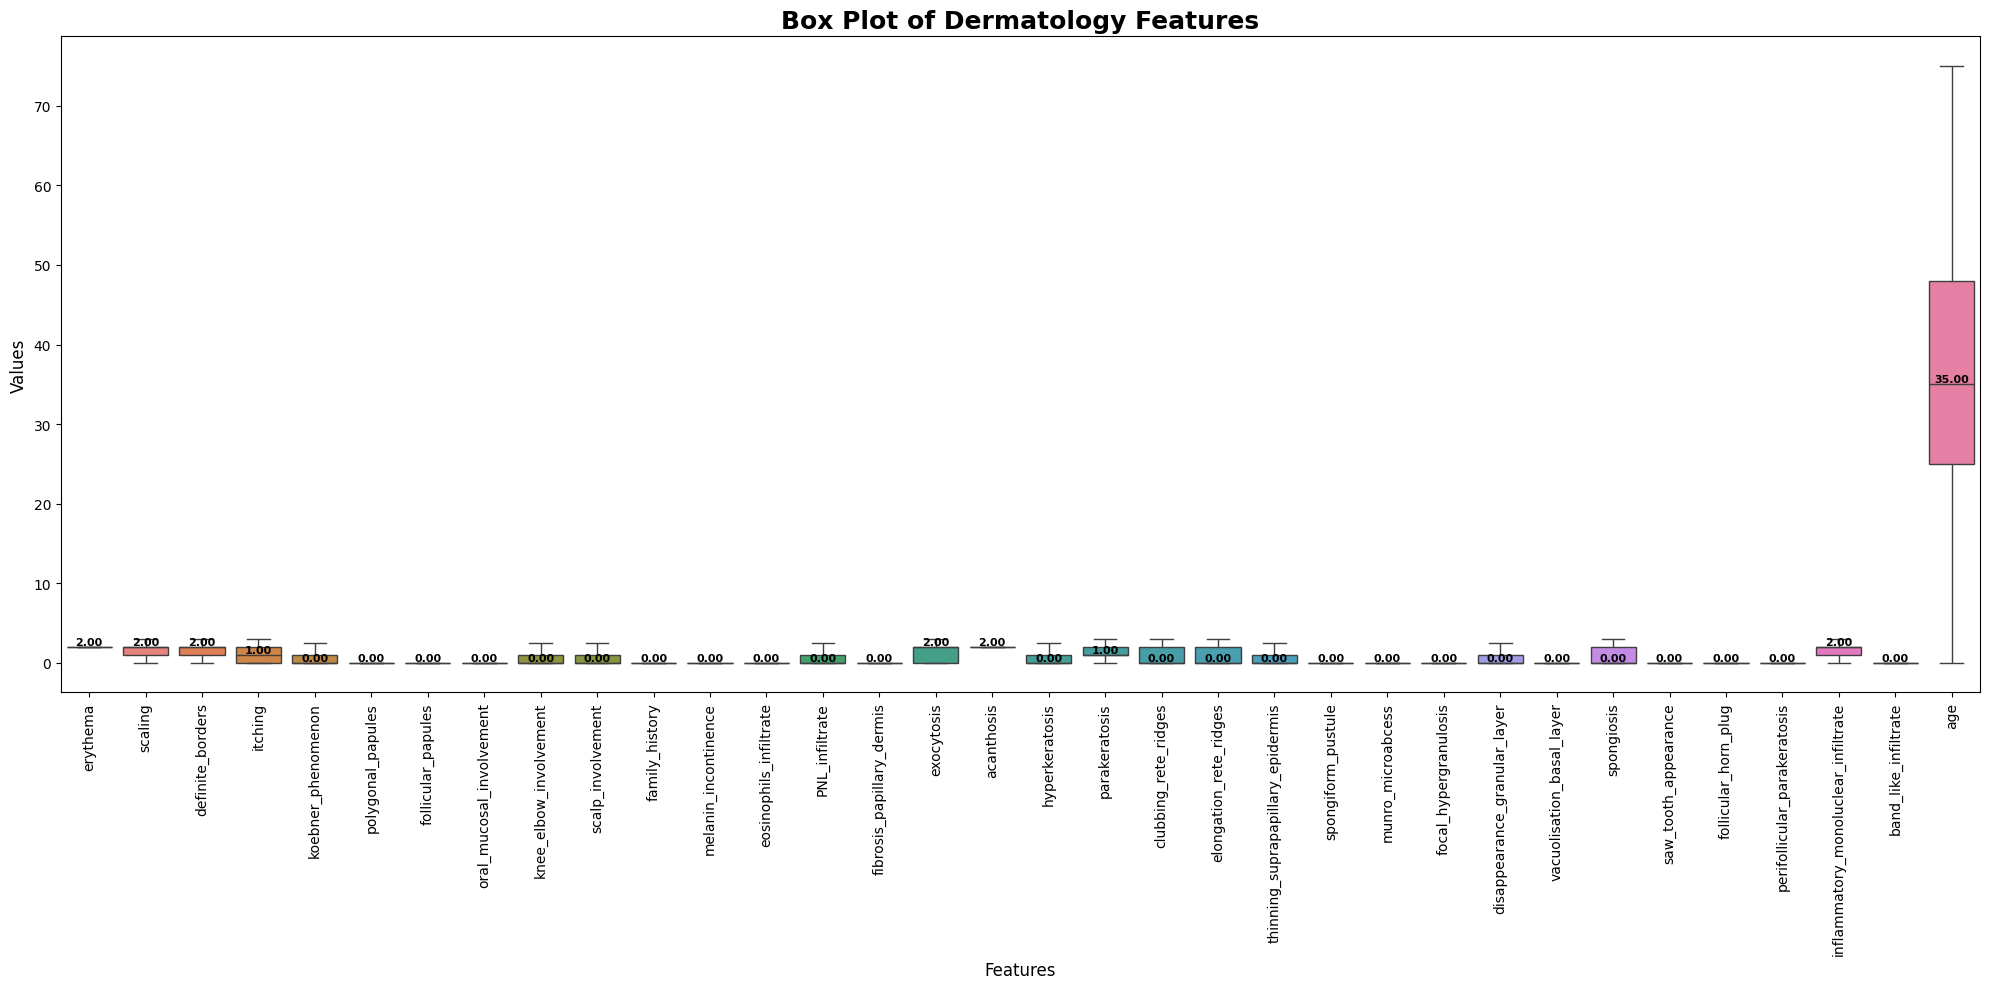

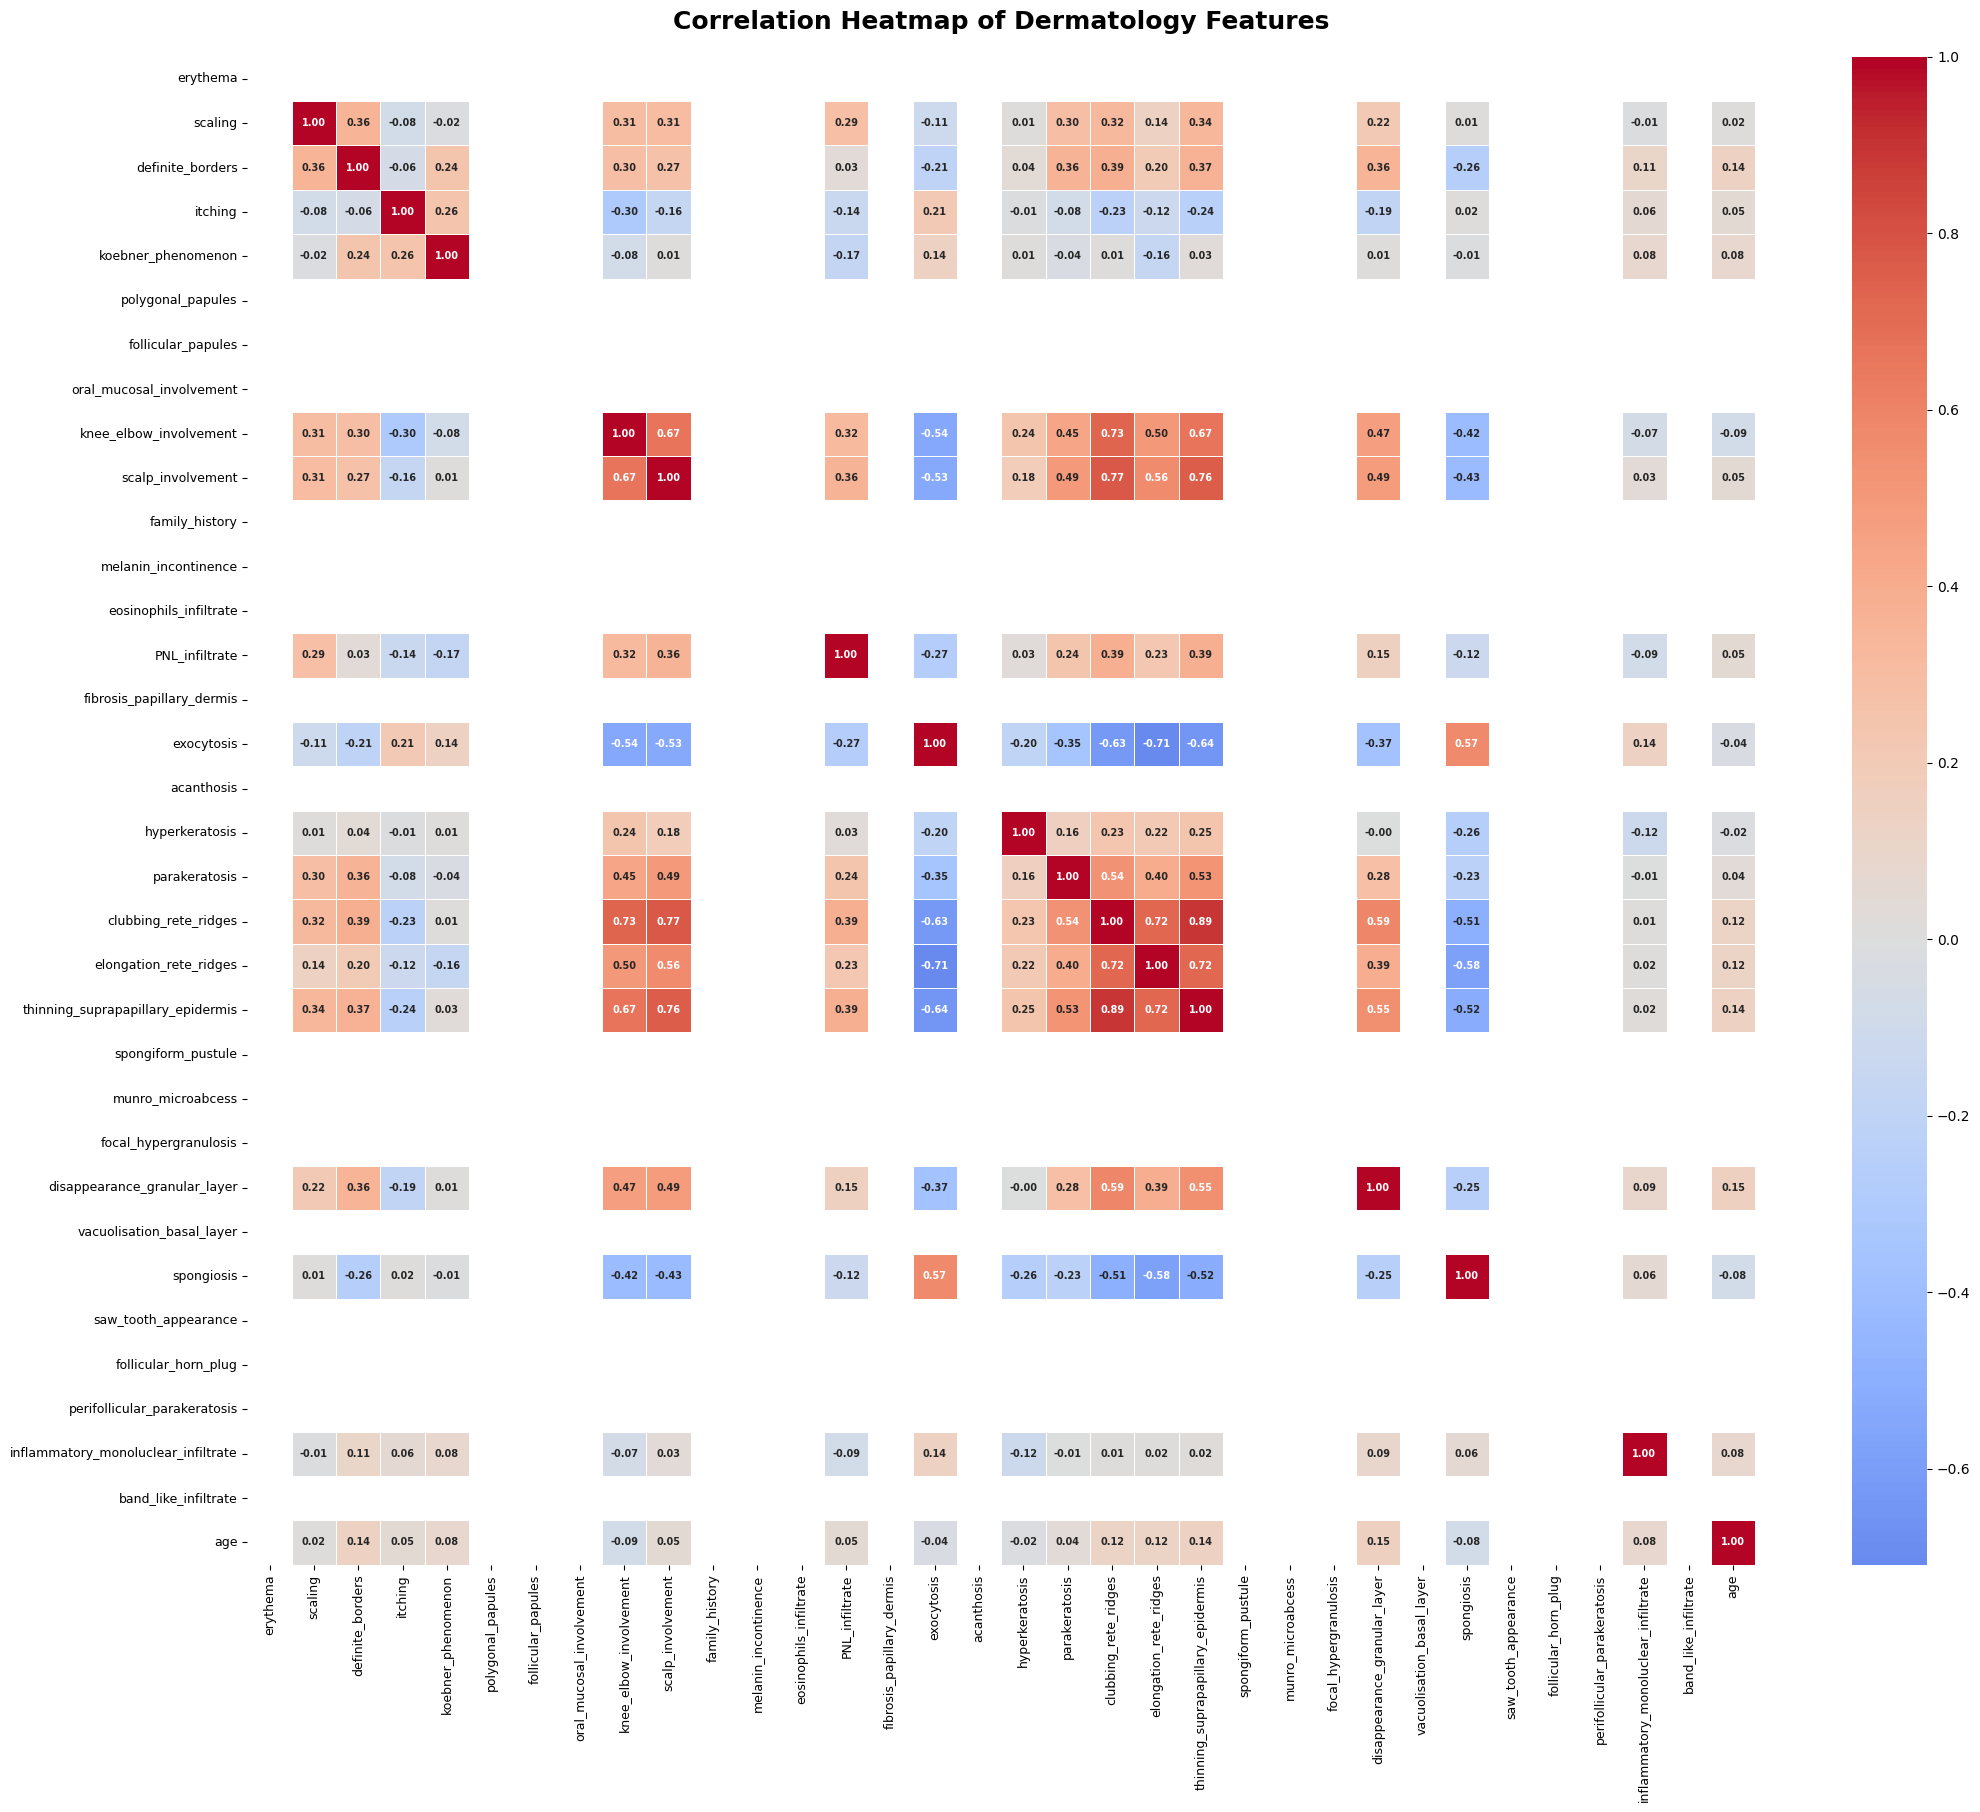

In [ ]:
# ============================================================
# 7. HISTOGRAMS
# ============================================================

X_clean.hist(
    figsize=(18, 20),
    bins=15
)

plt.suptitle(
    "Feature Distributions",
    fontsize=18
)

plt.tight_layout()
plt.show()


# ============================================================
# BOX PLOT WITH VALUES
# ============================================================

plt.figure(figsize=(20, 10))

# Create boxplot
ax = sns.boxplot(data=X_clean)

plt.title(
    "Box Plot of Dermatology Features",
    fontsize=18,
    fontweight="bold"
)

plt.xlabel(
    "Features",
    fontsize=12
)

plt.ylabel(
    "Values",
    fontsize=12
)

plt.xticks(
    rotation=90
)

# ------------------------------------------------------------
# ADD MEDIAN VALUES TO BOX PLOT
# ------------------------------------------------------------

for i, column in enumerate(X_clean.columns):

    median_value = X_clean[column].median()

    ax.text(
        i,
        median_value,
        f"{median_value:.2f}",
        ha="center",
        va="bottom",
        fontsize=8,
        fontweight="bold"
    )

plt.tight_layout()
plt.show()

# ============================================================
# CORRELATION HEATMAP WITH VALUES
# ============================================================

plt.figure(figsize=(22, 18))

# Calculate correlation matrix
correlation_matrix = X_clean.corr()

# Create heatmap
sns.heatmap(
    correlation_matrix,
    annot=True,              # SHOW VALUES
    fmt=".2f",               # TWO DECIMAL PLACES
    cmap="coolwarm",
    center=0,
    linewidths=0.5,
    square=True,
    annot_kws={
        "size": 7,
        "weight": "bold"
    }
)

plt.title(
    "Correlation Heatmap of Dermatology Features",
    fontsize=18,
    fontweight="bold",
    pad=20
)

plt.xticks(
    rotation=90,
    fontsize=9
)

plt.yticks(
    rotation=0,
    fontsize=9
)

plt.tight_layout()
plt.show()

In [ ]:
# ============================================================
# 9. TARGET ENCODING
# ============================================================

from sklearn.preprocessing import LabelEncoder

label_encoder = LabelEncoder()

y_encoded = label_encoder.fit_transform(y)

print("Original classes:")
print(label_encoder.classes_)

print("\nEncoded classes:")
print(np.unique(y_encoded))

Original classes:
[1 2 3 4 5 6]

Encoded classes:
[0 1 2 3 4 5]


In [ ]:
# ============================================================
# 10. TRAIN TEST SPLIT
# ============================================================

X_train, X_test, y_train, y_test = train_test_split(
    X_clean,
    y_encoded,
    test_size=0.20,
    random_state=42,
    stratify=y_encoded
)

print("Training samples:", X_train.shape[0])
print("Testing samples:", X_test.shape[0])

print("\nTraining class distribution:")
print(pd.Series(y_train).value_counts().sort_index())

print("\nTesting class distribution:")
print(pd.Series(y_test).value_counts().sort_index())

Training samples: 292
Testing samples: 74

Training class distribution:
0    89
1    49
2    57
3    39
4    42
5    16
Name: count, dtype: int64

Testing class distribution:
0    23
1    12
2    15
3    10
4    10
5     4
Name: count, dtype: int64


In [ ]:
# ============================================================
# 11. FEATURE STANDARDIZATION
# ============================================================

scaler = StandardScaler()

X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)

print("Feature standardization completed.")

print("\nTraining data shape:", X_train_scaled.shape)
print("Testing data shape:", X_test_scaled.shape)

Feature standardization completed.

Training data shape: (292, 34)
Testing data shape: (74, 34)


In [ ]:
# ============================================================
# 12. DEFINE MULTICLASS ML MODELS
# ============================================================

models = {

    "Logistic Regression": LogisticRegression(
        max_iter=5000,
        random_state=42
    ),

    "KNN": KNeighborsClassifier(
        n_neighbors=5
    ),

    "Random Forest": RandomForestClassifier(
        n_estimators=200,
        random_state=42
    ),

    "SVM": SVC(
        probability=True,
        random_state=42
    ),

    "Decision Tree": DecisionTreeClassifier(
        random_state=42
    )
}

print("Models created:")
for model_name in models:
    print("-", model_name)

Models created:
- Logistic Regression
- KNN
- Random Forest
- SVM
- Decision Tree


In [ ]:
# ============================================================
# 13. TRAIN MODELS
# ============================================================

trained_models = {}

for name, model in models.items():

    print(f"\nTraining {name}...")

    model.fit(
        X_train_scaled,
        y_train
    )

    trained_models[name] = model

print("\nAll models trained successfully!")


Training Logistic Regression...

Training KNN...

Training Random Forest...

Training SVM...

Training Decision Tree...

All models trained successfully!


In [ ]:
# ============================================================
# 14. PREDICTIONS
# ============================================================

predictions = {}

for name, model in trained_models.items():

    predictions[name] = model.predict(
        X_test_scaled
    )

print("Predictions generated for all models.")

Predictions generated for all models.


In [ ]:
# ============================================================
# 15. MODEL EVALUATION
# ============================================================

results = []

for name in trained_models:

    y_pred = predictions[name]

    accuracy = accuracy_score(
        y_test,
        y_pred
    )

    precision = precision_score(
        y_test,
        y_pred,
        average="weighted",
        zero_division=0
    )

    recall = recall_score(
        y_test,
        y_pred,
        average="weighted",
        zero_division=0
    )

    f1 = f1_score(
        y_test,
        y_pred,
        average="weighted",
        zero_division=0
    )

    results.append([
        name,
        accuracy,
        precision,
        recall,
        f1
    ])

results_df = pd.DataFrame(
    results,
    columns=[
        "Model",
        "Accuracy",
        "Precision",
        "Recall",
        "F1 Score"
    ]
)

display(results_df.round(4))

,Model,Accuracy,Precision,Recall,F1 Score
0,Logistic Regression,0.9595,0.9588,0.9595,0.9586
1,KNN,0.9189,0.9221,0.9189,0.9141
2,Random Forest,0.9459,0.9472,0.9459,0.9460
3,SVM,0.9730,0.9730,0.9730,0.9730
4,Decision Tree,0.9054,0.9168,0.9054,0.9066


In [ ]:
# ============================================================
# 16. CLASSIFICATION REPORT
# ============================================================

for name in trained_models:

    print("\n")
    print("=" * 70)
    print(name)
    print("=" * 70)

    print(
        classification_report(
            y_test,
            predictions[name],
            target_names=[
                "Class 1",
                "Class 2",
                "Class 3",
                "Class 4",
                "Class 5",
                "Class 6"
            ],
            zero_division=0
        )
    )



Logistic Regression
              precision    recall  f1-score   support

     Class 1       1.00      1.00      1.00        23
     Class 2       0.92      0.92      0.92        12
     Class 3       0.94      1.00      0.97        15
     Class 4       0.89      0.80      0.84        10
     Class 5       1.00      1.00      1.00        10
     Class 6       1.00      1.00      1.00         4

    accuracy                           0.96        74
   macro avg       0.96      0.95      0.95        74
weighted avg       0.96      0.96      0.96        74



KNN
              precision    recall  f1-score   support

     Class 1       1.00      1.00      1.00        23
     Class 2       0.88      0.58      0.70        12
     Class 3       0.88      1.00      0.94        15
     Class 4       0.75      0.90      0.82        10
     Class 5       1.00      1.00      1.00        10
     Class 6       1.00      1.00      1.00         4

    accuracy                           0.92      

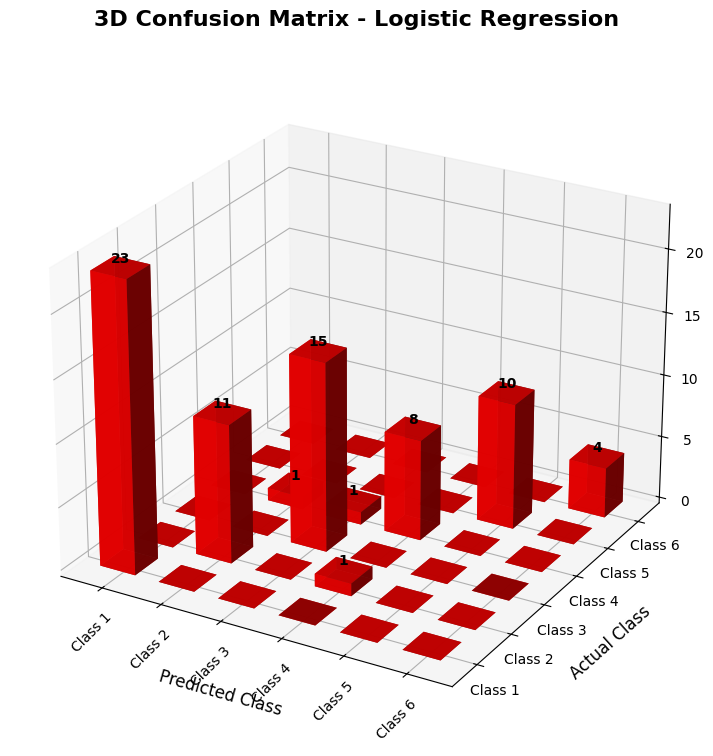

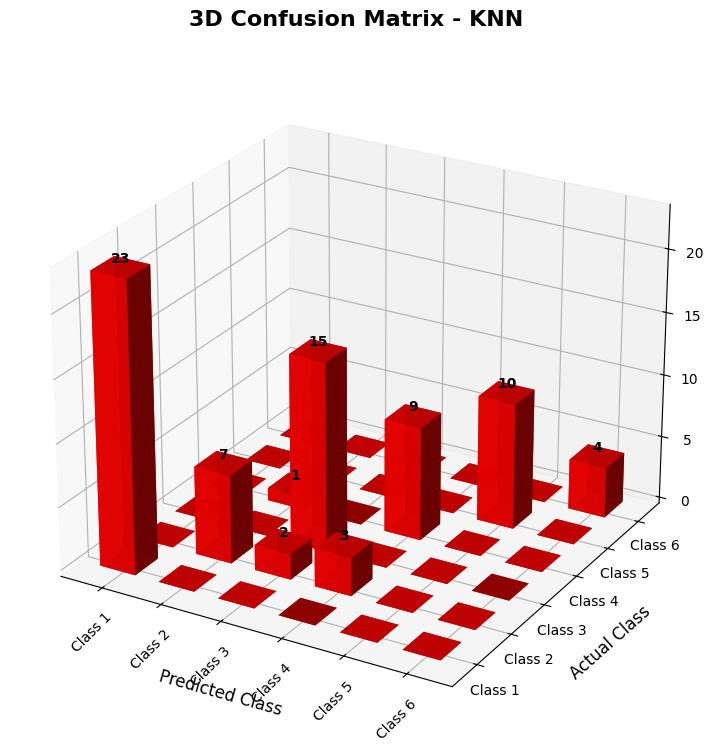

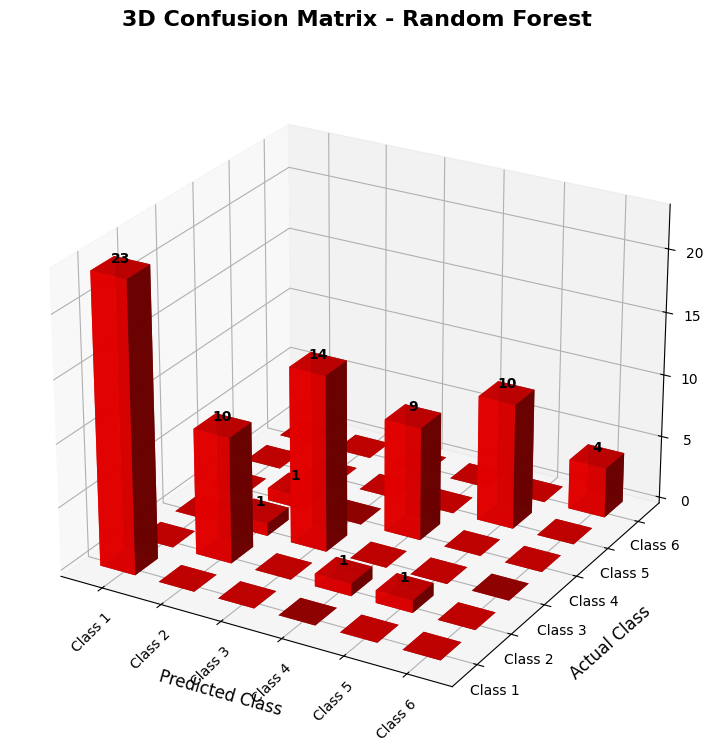

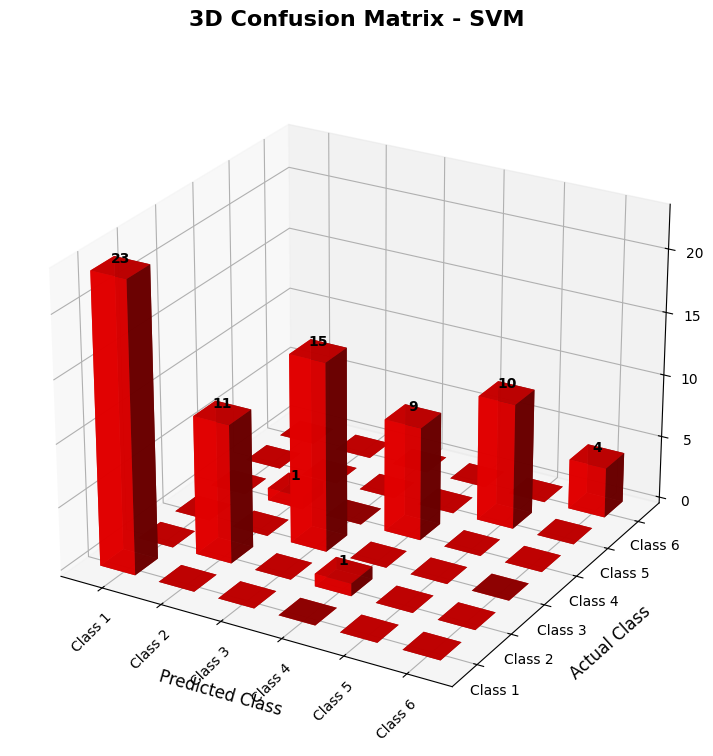

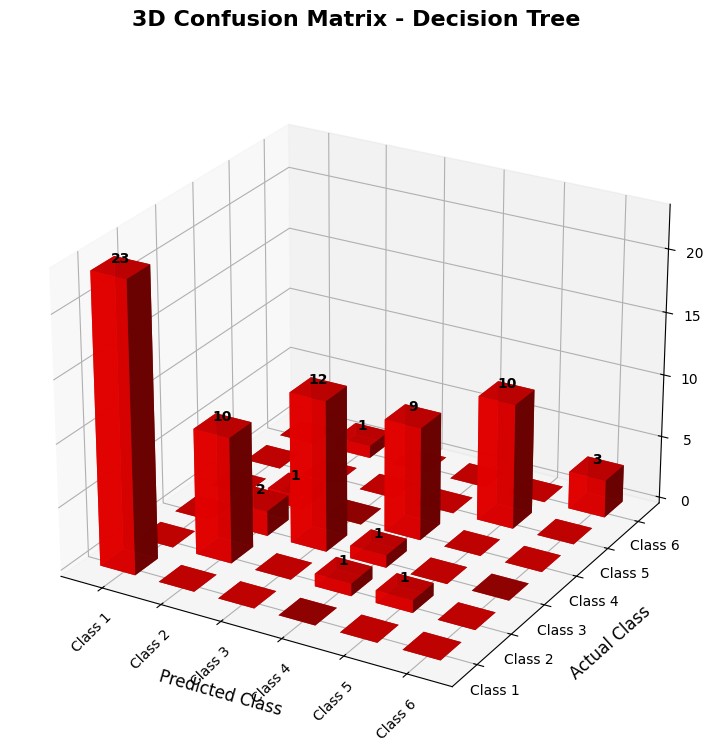

In [ ]:
# ============================================================
# 3D CONFUSION MATRIX - RED COLOR
# ============================================================

def plot_3d_confusion_matrix(
    y_true,
    y_pred,
    title
):

    # Calculate confusion matrix
    cm = confusion_matrix(
        y_true,
        y_pred
    )

    # Number of classes
    n_classes = cm.shape[0]

    # X and Y positions
    x_positions = np.arange(n_classes)
    y_positions = np.arange(n_classes)

    x_grid, y_grid = np.meshgrid(
        x_positions,
        y_positions
    )

    x = x_grid.flatten()
    y = y_grid.flatten()

    # Z starting position
    z = np.zeros_like(x)

    # Bar dimensions
    dx = 0.6 * np.ones_like(x)
    dy = 0.6 * np.ones_like(y)

    # Bar heights = confusion matrix values
    dz = cm.flatten()

    # --------------------------------------------------------
    # CREATE 3D FIGURE
    # --------------------------------------------------------

    fig = plt.figure(
        figsize=(12, 9)
    )

    ax = fig.add_subplot(
        111,
        projection="3d"
    )

    # --------------------------------------------------------
    # RED 3D BARS
    # --------------------------------------------------------

    ax.bar3d(
        x,
        y,
        z,
        dx,
        dy,
        dz,
        color="red",       # RED COLOR
        shade=True,
        alpha=0.9
    )

    # --------------------------------------------------------
    # AXIS LABELS
    # --------------------------------------------------------

    ax.set_xlabel(
        "Predicted Class",
        labelpad=12,
        fontsize=12
    )

    ax.set_ylabel(
        "Actual Class",
        labelpad=12,
        fontsize=12
    )

    ax.set_zlabel(
        "Number of Samples",
        labelpad=12,
        fontsize=12
    )

    # --------------------------------------------------------
    # CLASS LABELS
    # --------------------------------------------------------

    class_labels = [
        "Class 1",
        "Class 2",
        "Class 3",
        "Class 4",
        "Class 5",
        "Class 6"
    ]

    ax.set_xticks(
        x_positions + 0.3
    )

    ax.set_yticks(
        y_positions + 0.3
    )

    ax.set_xticklabels(
        class_labels,
        rotation=45
    )

    ax.set_yticklabels(
        class_labels
    )

    # --------------------------------------------------------
    # TITLE
    # --------------------------------------------------------

    ax.set_title(
        "3D Confusion Matrix - " + title,
        fontsize=16,
        fontweight="bold",
        pad=20
    )

    # --------------------------------------------------------
    # ADD VALUES ON TOP OF BARS
    # --------------------------------------------------------

    for i in range(n_classes):

        for j in range(n_classes):

            value = cm[i, j]

            if value > 0:

                ax.text(
                    j + 0.3,
                    i + 0.3,
                    value + 0.2,
                    str(value),
                    ha="center",
                    va="bottom",
                    fontsize=10,
                    fontweight="bold"
                )

    # --------------------------------------------------------
    # VIEW ANGLE
    # --------------------------------------------------------

    ax.view_init(
        elev=25,
        azim=-60
    )

    plt.tight_layout()
    plt.show()

    # ============================================================
# PLOT 3D RED CONFUSION MATRICES FOR ALL MODELS
# ============================================================

for name in trained_models:

    plot_3d_confusion_matrix(
        y_test,
        predictions[name],
        name
    )

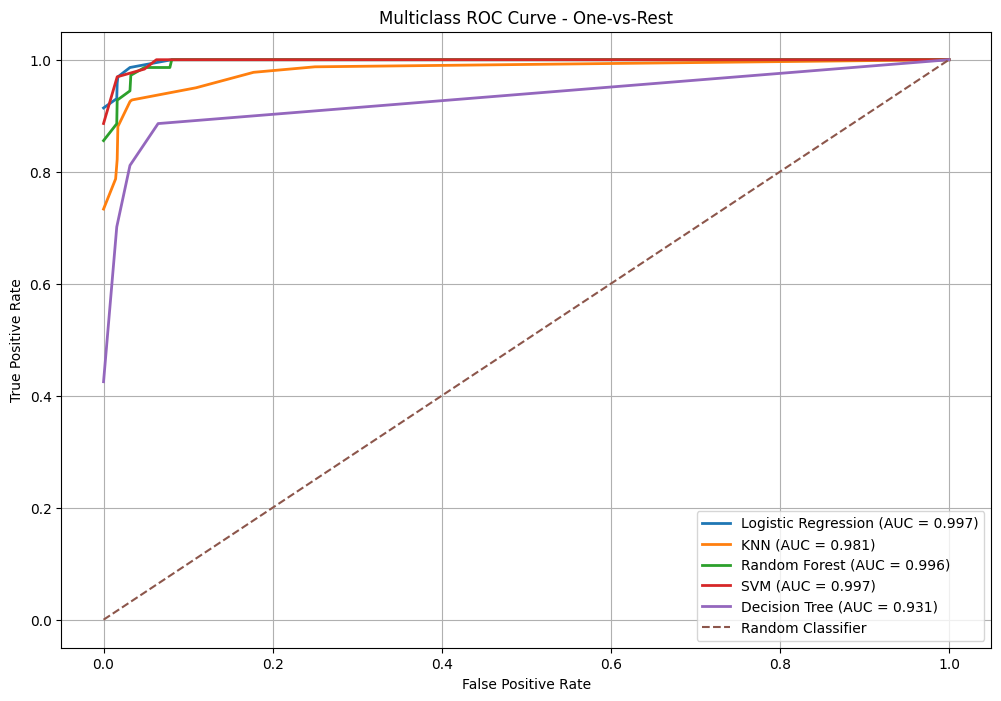

In [ ]:
# ============================================================
# 18. MULTICLASS ROC CURVES
# ============================================================

# Convert target into one-hot representation
n_classes = len(np.unique(y_test))

y_test_bin = label_binarize(
    y_test,
    classes=np.arange(n_classes)
)

plt.figure(figsize=(12, 8))

auc_scores = {}

for name, model in trained_models.items():

    # Probability predictions
    y_score = model.predict_proba(
        X_test_scaled
    )

    # Calculate macro AUC
    macro_auc = roc_auc_score(
        y_test_bin,
        y_score,
        multi_class="ovr",
        average="macro"
    )

    auc_scores[name] = macro_auc

    # Calculate micro-average ROC
    fpr = {}
    tpr = {}

    for i in range(n_classes):

        fpr[i], tpr[i], _ = roc_curve(
            y_test_bin[:, i],
            y_score[:, i]
        )

    # Combine all classes
    all_fpr = np.unique(
        np.concatenate([
            fpr[i] for i in range(n_classes)
        ])
    )

    mean_tpr = np.zeros_like(all_fpr)

    for i in range(n_classes):

        mean_tpr += np.interp(
            all_fpr,
            fpr[i],
            tpr[i]
        )

    mean_tpr /= n_classes

    plt.plot(
        all_fpr,
        mean_tpr,
        linewidth=2,
        label=f"{name} (AUC = {macro_auc:.3f})"
    )

# Random classifier line
plt.plot(
    [0, 1],
    [0, 1],
    linestyle="--",
    label="Random Classifier"
)

plt.xlabel("False Positive Rate")
plt.ylabel("True Positive Rate")

plt.title(
    "Multiclass ROC Curve - One-vs-Rest"
)

plt.legend(
    loc="lower right"
)

plt.grid(True)

plt.show()

,Model,AUC
0,Logistic Regression,0.9975
1,KNN,0.9814
2,Random Forest,0.9957
3,SVM,0.9969
4,Decision Tree,0.9310


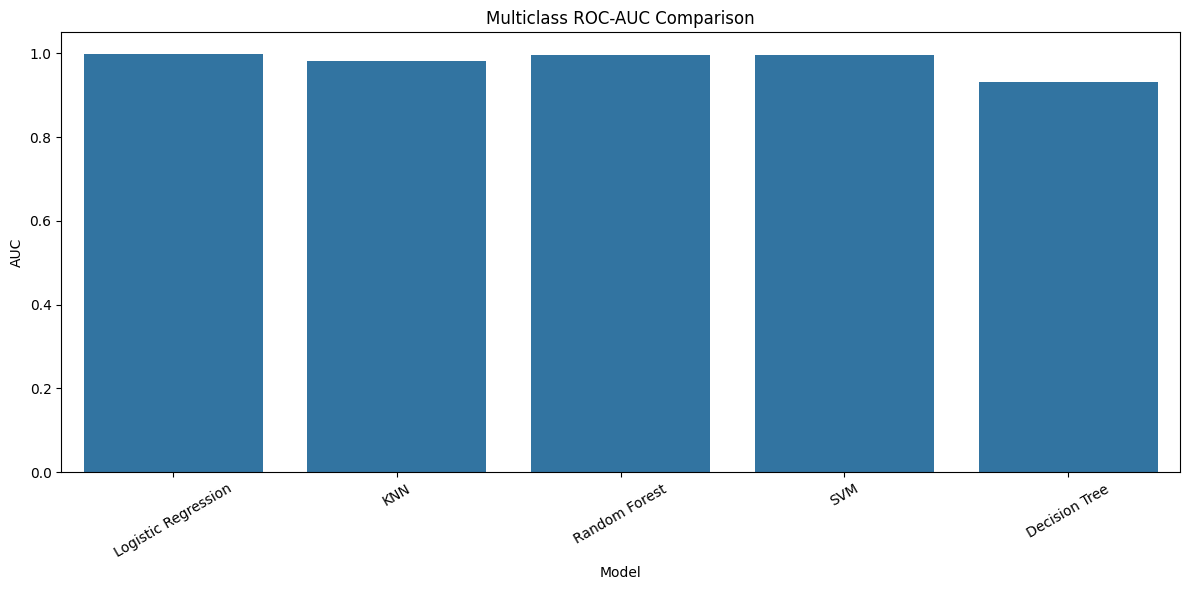

In [ ]:
# ============================================================
# 20. AUC COMPARISON
# ============================================================

auc_df = pd.DataFrame(
    list(auc_scores.items()),
    columns=["Model", "AUC"]
)

display(
    auc_df.round(4)
)

plt.figure(figsize=(12, 6))

sns.barplot(
    data=auc_df,
    x="Model",
    y="AUC"
)

plt.title(
    "Multiclass ROC-AUC Comparison"
)

plt.ylim(0, 1.05)

plt.xticks(
    rotation=30
)

plt.tight_layout()
plt.show()

In [ ]:
# ============================================================
# 21. PER-CLASS PERFORMANCE
# ============================================================

all_class_results = []

class_names = [
    "Class 1",
    "Class 2",
    "Class 3",
    "Class 4",
    "Class 5",
    "Class 6"
]

for name in trained_models:

    report = classification_report(
        y_test,
        predictions[name],
        target_names=class_names,
        output_dict=True,
        zero_division=0
    )

    for class_name in class_names:

        all_class_results.append([
            name,
            class_name,
            report[class_name]["precision"],
            report[class_name]["recall"],
            report[class_name]["f1-score"]
        ])

per_class_df = pd.DataFrame(
    all_class_results,
    columns=[
        "Model",
        "Class",
        "Precision",
        "Recall",
        "F1 Score"
    ]
)

display(
    per_class_df.round(4)
)

,Model,Class,Precision,Recall,F1 Score
0,Logistic Regression,Class 1,1.0000,1.0000,1.0000
1,Logistic Regression,Class 2,0.9167,0.9167,0.9167
2,Logistic Regression,Class 3,0.9375,1.0000,0.9677
3,Logistic Regression,Class 4,0.8889,0.8000,0.8421
4,Logistic Regression,Class 5,1.0000,1.0000,1.0000
5,Logistic Regression,Class 6,1.0000,1.0000,1.0000
6,KNN,Class 1,1.0000,1.0000,1.0000
7,KNN,Class 2,0.8750,0.5833,0.7000
8,KNN,Class 3,0.8824,1.0000,0.9375
9,KNN,Class 4,0.7500,0.9000,0.8182
